# Final Notebook

In [8]:
import json,time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import xgboost as xgb, lightgbm as lgb
from scipy.optimize import minimize
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss, precision_recall_fscore_support
from sklearn.model_selection import (GridSearchCV, GroupShuffleSplit, RandomizedSearchCV, StratifiedGroupKFold,
                                     StratifiedKFold, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [ ]:
import warnings
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); pd.set_option('display.width', 170)

In [3]:
sample_sub=pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/sample_submission.csv")
test=pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/test.csv")
train=pd.read_csv("/kaggle/input/competitions/workstation-rental-price-tier-prediction/kaggle_ready_dataset/train.csv")

In [7]:
print("train shape:",train.shape)
print("test shape:",test.shape)

train shape: (279746, 60)
test shape: (114538, 59)


In [11]:
import os
QUICK = False                      # True = 5-minute smoke test on a small slice; False = the real run
SEED, N_JOBS = 42, os.cpu_count()
N_SAMPLE = 6000 if QUICK else 80000                          # rows used for the model-selection experiments (Step 5)
N_ITER = dict(rf=2, xgb=2) if QUICK else dict(rf=6, xgb=8)   # random-search budgets
MAX_TREES = 60 if QUICK else 3000  

# Exploratory data analysis

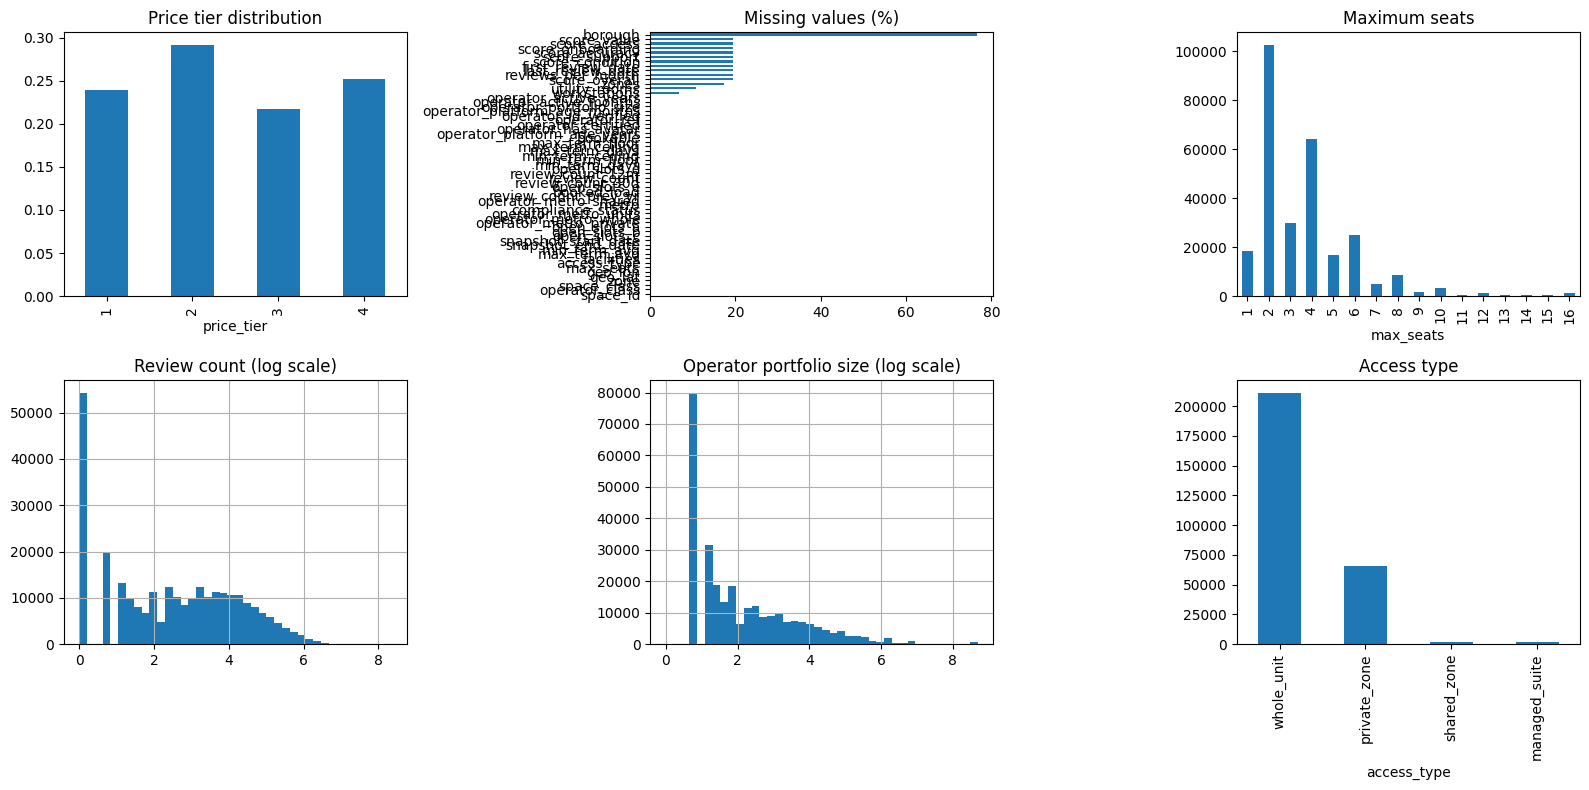

Most skewed numeric columns:
max_term_floor             200.2
max_term_avg               166.1
max_term_ceiling           118.3
max_term_days              118.3
operator_metro_shared       23.2
operator_portfolio_size     16.1
dtype: float64

max_term_days:
Median: 365.0
99.9th percentile: 1125.0
Maximum: 577341108.0

Example facilities: ["FCL-087", "FCL-007", "FCL-085", "FCL-072", "FCL-035", "FCL-115", "FC
Therefore -JSON list stored as text

Review columns missing when review_count == 0: True


In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))

train['price_tier'].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0, 0])
ax[0, 0].set_title('Price tier distribution')

(train.drop(columns='price_tier').isna().mean() * 100).sort_values().plot.barh(ax=ax[0, 1])
ax[0, 1].set_title('Missing values (%)')

train['max_seats'].clip(upper=16).value_counts().sort_index().plot.bar(ax=ax[0, 2])
ax[0, 2].set_title('Maximum seats')

np.log1p(train['review_count']).hist(ax=ax[1, 0], bins=40)
ax[1, 0].set_title('Review count (log scale)')

np.log1p(train['operator_portfolio_size']).hist(ax=ax[1, 1], bins=40)
ax[1, 1].set_title('Operator portfolio size (log scale)')

train['access_type'].value_counts().plot.bar(ax=ax[1, 2])
ax[1, 2].set_title('Access type')

plt.tight_layout()
plt.show()


num = train.select_dtypes('number').drop(columns=['space_id', 'price_tier'])

print('Most skewed numeric columns:')
print(num.skew().abs().sort_values(ascending=False).head(6).round(1))

print('\nmax_term_days:')
print('Median:', train.max_term_days.median())
print('99.9th percentile:', train.max_term_days.quantile(.999))
print('Maximum:', train.max_term_days.max())

print('\nExample facilities:', train.facilities.iloc[0][:70])
print('Therefore -JSON list stored as text')

print('\nReview columns missing when review_count == 0:',
      (train.score_overall.isna() == (train.review_count == 0)).mean() > .99)

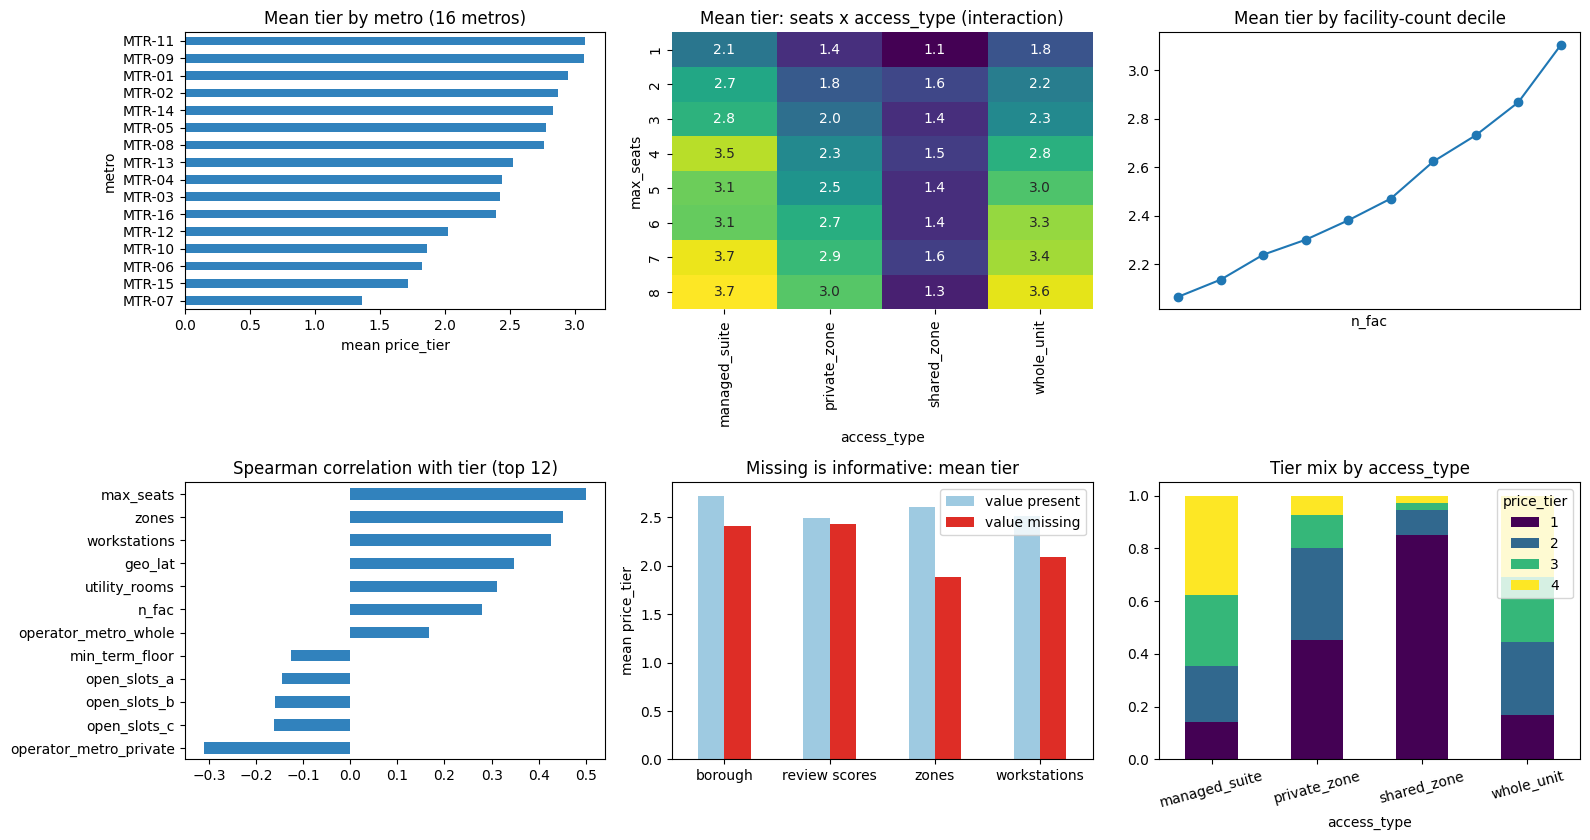

access_type  managed_suite  private_zone  shared_zone  whole_unit
max_seats                                                        
1                     2.12          1.43         1.07        1.77
2                     2.67          1.82         1.64        2.20
3                     2.79          2.04         1.42        2.33
4                     3.45          2.33         1.54        2.76
5                     3.14          2.46         1.42        3.00
6                     3.11          2.75         1.43        3.32
7                     3.67          2.87         1.57        3.37
8                     3.74          3.04         1.30        3.64


In [10]:
# ============ Step 2b: bivariate EDA ============
t = train.copy(); t['n_fac'] = t['facilities'].map(lambda s: len(json.loads(s)))
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
t.groupby('metro').price_tier.mean().sort_values().plot.barh(ax=ax[0, 0], color='#3182bd'); ax[0, 0].set_title('Mean tier by metro (16 metros)'); ax[0, 0].set_xlabel('mean price_tier')
piv = t.groupby([t.max_seats.clip(upper=8), 'access_type']).price_tier.mean().unstack()
sns.heatmap(piv, annot=True, fmt='.1f', cmap='viridis', ax=ax[0, 1], cbar=False); ax[0, 1].set_title('Mean tier: seats x access_type (interaction)')
t.groupby(pd.qcut(t.n_fac, 10, duplicates='drop'), observed=True).price_tier.mean().plot(marker='o', ax=ax[0, 2]); ax[0, 2].set_title('Mean tier by facility-count decile'); ax[0, 2].set_xticks([])
cor = t.select_dtypes('number').drop(columns=['space_id', 'price_tier']).corrwith(t.price_tier, method='spearman').dropna()
cor.reindex(cor.abs().sort_values(ascending=False).head(12).index).sort_values().plot.barh(ax=ax[1, 0], color='#3182bd'); ax[1, 0].set_title('Spearman correlation with tier (top 12)')
flags = {'borough': t.borough.isna(), 'review scores': t.score_overall.isna(), 'zones': t.zones.isna(), 'workstations': t.workstations.isna()}
pd.DataFrame({k: [t.price_tier[~v].mean(), t.price_tier[v].mean()] for k, v in flags.items()}, index=['value present', 'value missing']).T.plot.bar(ax=ax[1, 1], rot=0, color=['#9ecae1', '#de2d26'])
ax[1, 1].set_title('Missing is informative: mean tier'); ax[1, 1].set_ylabel('mean price_tier')
pd.crosstab(t.access_type, t.price_tier, normalize='index').plot.bar(stacked=True, ax=ax[1, 2], rot=15, colormap='viridis'); ax[1, 2].set_title('Tier mix by access_type')
plt.tight_layout(); plt.show()
print(piv.round(2).to_string())

hosts in train: 134321 | listings per host: median 1, max 773 | hosts with one listing: 74% of hosts
tier std overall 1.11 vs INSIDE a host 0.53  -> listings of one host price alike
share of TEST listings whose host also appears in train: 0.45%  -> test hosts are (almost) new hosts
distinct coordinate pairs: 12849 for 279746 rows; 98.4% of test coordinates also occur in train -> coordinates sit on a coarse grid of "cells"
train-vs-test mix difference (total variation): metro 0.09, zone 0.13 -> test listings come from a different location mix


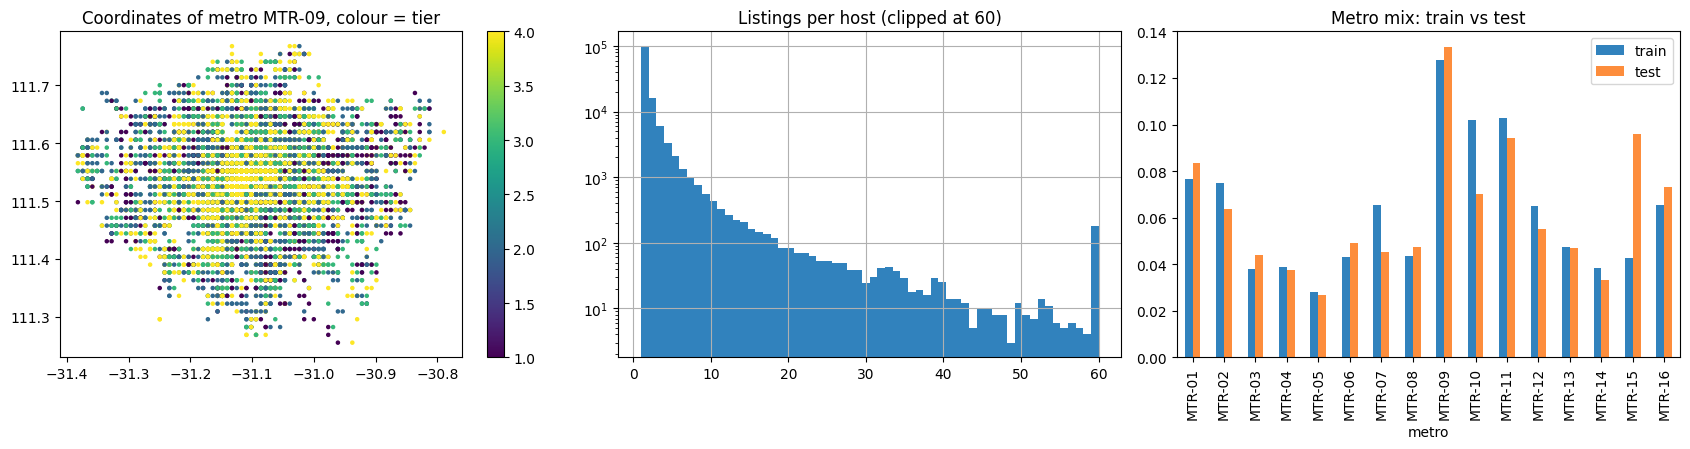

In [6]:
# ============ Step 2c: hosts, coordinates and train/test shift ============
PROFILE = ['operator_ref', 'operator_platform_age_years', 'operator_platform_age_months', 'operator_active_years', 'operator_active_months',
           'operator_portfolio_size', 'operator_class', 'operator_certified', 'operator_has_avatar', 'operator_id_verified']
def host_key(raw):
    # a host = operator name + operator profile values; rows without a name become their own host
    k = raw[PROFILE[0]].astype(str)
    for c in PROFILE[1:]: k = k + '|' + raw[c].astype(str)
    return k.where(raw['operator_ref'].notna(), pd.Series('unk_' + raw.index.astype(str), index=raw.index))

hk_tr0, hk_te0 = host_key(train), host_key(test)
size = hk_tr0.map(hk_tr0.value_counts()); multi = size > 1
within = np.sqrt((train.price_tier - train.groupby(hk_tr0).price_tier.transform('mean'))[multi].pow(2).mean())
print('hosts in train: %d | listings per host: median %d, max %d | hosts with one listing: %.0f%% of hosts' % (
      hk_tr0.nunique(), hk_tr0.value_counts().median(), hk_tr0.value_counts().max(), 100 * (hk_tr0.value_counts() == 1).mean()))
print('tier std overall %.2f vs INSIDE a host %.2f  -> listings of one host price alike' % (train.price_tier.std(), within))
print('share of TEST listings whose host also appears in train: %.2f%%  -> test hosts are (almost) new hosts' % (100 * hk_te0.isin(set(hk_tr0)).mean()))
cells = train.groupby(['geo_lat', 'geo_lon']).ngroup()
print('distinct coordinate pairs: %d for %d rows; %.1f%% of test coordinates also occur in train -> coordinates sit on a coarse grid of "cells"' % (
      cells.nunique(), len(train), 100 * test[['geo_lat', 'geo_lon']].apply(tuple, axis=1).isin(set(zip(train.geo_lat, train.geo_lon))).mean()))
tv = lambda a, b: 0.5 * a.value_counts(normalize=True).sub(b.value_counts(normalize=True), fill_value=0).abs().sum()
print('train-vs-test mix difference (total variation): metro %.2f, zone %.2f -> test listings come from a different location mix' % (tv(train.metro, test.metro), tv(train.zone, test.zone)))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
big = train.metro.value_counts().index[0]; s = train[train.metro == big].sample(min(15000, (train.metro == big).sum()), random_state=0)
sc = ax[0].scatter(s.geo_lon, s.geo_lat, c=s.price_tier, cmap='viridis', s=5); ax[0].set_title(f'Coordinates of metro {big}, colour = tier'); plt.colorbar(sc, ax=ax[0])
hk_tr0.value_counts().clip(upper=60).hist(bins=60, ax=ax[1], color='#3182bd'); ax[1].set_yscale('log'); ax[1].set_title('Listings per host (clipped at 60)')
pd.DataFrame({'train': train.metro.value_counts(normalize=True), 'test': test.metro.value_counts(normalize=True)}).sort_index().plot.bar(ax=ax[2], color=['#3182bd', '#fd8d3c']); ax[2].set_title('Metro mix: train vs test')
plt.tight_layout(); plt.show()

# Preprocessing

In [9]:
# ============ Step 3a: the reusable feature function ============
DATES = ['snapshot_start_date', 'snapshot_end_date', 'first_review_date', 'last_review_date']
CATS = ['operator_class', 'operator_certified', 'operator_has_avatar', 'operator_id_verified', 'zone', 'borough', 'space_class',
        'access_type', 'bookable', 'compliance_status', 'metro']
OP_CONST = ['operator_portfolio_size', 'operator_metro_units', 'operator_metro_whole', 'operator_metro_private', 'operator_metro_shared']
SCORES = ['score_accuracy', 'score_condition', 'score_onboarding', 'score_support', 'score_access', 'score_value']

def build_features(raw):
    hk = host_key(raw)
    df = raw.drop(columns=['space_id', 'price_tier'], errors='ignore').copy()
    # --- list column -> count and one flag per facility
    fac = df.pop('facilities').fillna('[]').map(json.loads)
    mlb = MultiLabelBinarizer()
    F = pd.DataFrame(mlb.fit_transform(fac).astype(np.uint8), columns=['f_' + c for c in mlb.classes_], index=df.index)
    df['n_facilities'] = fac.map(len)
    # --- dates -> durations
    for c in DATES: df[c] = pd.to_datetime(df[c], errors='coerce')
    base = df['snapshot_start_date']
    df['snap_span_days'] = (df['snapshot_end_date'] - base).dt.days
    df['days_since_first_review'] = (base - df['first_review_date']).dt.days
    df['days_since_last_review'] = (base - df['last_review_date']).dt.days
    df['snap_month'] = base.dt.month
    for c in DATES: df[c] = (df[c] - pd.Timestamp('2000-01-01')).dt.days
    # --- missing-value flags (missingness is informative)
    for c in ['zones', 'utility_rooms', 'workstations', 'borough', 'operator_ref']: df[c + '_missing'] = df[c].isna().astype(np.int8)
    df['no_reviews'] = (df['review_count'] == 0).astype(np.int8)
    # --- outliers, ratios, interactions
    df['max_term_clip'] = df['max_term_days'].clip(upper=3650)
    df['avail_a'] = df['open_slots_a'] / 30; df['avail_d'] = df['open_slots_d'] / 365; df['avail_trend'] = df['avail_a'] - df['avail_d']
    df['seats_per_ws'] = df['max_seats'] / df['workstations']; df['seats_per_room'] = df['max_seats'] / df['utility_rooms']
    df['ws_per_room'] = df['workstations'] / df['utility_rooms']
    df['rev12_share'] = df['review_count_12m'] / df['review_count'].replace(0, np.nan)
    df['score_min'] = df[SCORES].min(axis=1); df['score_mean'] = df[SCORES].mean(axis=1)
    # --- listing relative to its zone / metro (features only, no target)
    for name, key in [('zn', df['zone']), ('mt', df['metro'])]:
        g = df.groupby(key)
        for c in ['max_seats', 'workstations', 'utility_rooms', 'min_term_days', 'booked_load', 'n_facilities', 'score_overall']:
            m = g[c].transform('mean'); df[f'{name}_diff_{c}'] = df[c] - m
            if name == 'zn': df[f'zn_mean_{c}'] = m
        df[f'{name}_rank_seats'] = g['max_seats'].rank(pct=True)
    df['zn_size'] = df.groupby('zone')['max_seats'].transform('size')
    # --- host features
    g = df.groupby(hk)
    df['host_size'] = g['max_seats'].transform('size'); df['host_nzone'] = g['zone'].transform('nunique')
    df['host_nmetro'] = g['metro'].transform('nunique'); df['host_nclass'] = g['space_class'].transform('nunique')
    for c in ['max_seats', 'workstations', 'utility_rooms', 'zones', 'min_term_days', 'n_facilities', 'open_slots_d', 'booked_load',
              'score_overall', 'review_count', 'zn_diff_max_seats', 'mt_diff_max_seats', 'zn_diff_min_term_days', 'zn_diff_n_facilities']:
        m = g[c].transform('mean'); df[f'host_mean_{c}'] = m; df[f'host_diff_{c}'] = df[c] - m
    df['host_std_seats'] = g['max_seats'].transform('std'); df['host_rank_seats'] = g['max_seats'].rank(pct=True)
    df['host_frac_whole'] = (df['access_type'] == 'whole_unit').groupby(hk).transform('mean')
    df['host_first_snapshot'] = g['snapshot_start_date'].transform('min')
    df['host_snapshot_span'] = g['snapshot_start_date'].transform('max') - df['host_first_snapshot']
    # --- coarsen exact host constants (a deep model could otherwise memorise hosts), drop redundant column families
    for c in OP_CONST: df[c + '_b'] = np.floor(np.log2(1 + df[c])).astype('float32')
    df['operator_age_b'] = df['operator_platform_age_years'] // 3
    df = df.drop(columns=['min_term_floor', 'min_term_ceiling', 'max_term_floor', 'max_term_ceiling', 'max_term_days', 'operator_platform_age_months',
                          'operator_active_months', 'operator_platform_age_years', 'operator_active_years', 'operator_ref'] + OP_CONST)
    # --- encoding: category text -> integer codes (NaN stays NaN)
    for c in CATS: df[c] = df[c].astype('category').cat.codes.replace(-1, np.nan).astype('float')
    X = pd.concat([df, F], axis=1).replace([np.inf, -np.inf], np.nan)
    for c in X.columns:
        if X[c].dtype == 'float64': X[c] = X[c].astype('float32')
    return X, hk

t0 = time.time()
both = pd.concat([train, test], ignore_index=True)           # train and test processed together -> identical columns
X_all, hk_all = build_features(both)
n_tr = len(train)
print('feature table:', X_all.shape, '| %d raw columns -> %d model columns | %.0fs' % (both.shape[1] - 2, X_all.shape[1], time.time() - t0))
print('first 12 engineered columns:', [c for c in X_all.columns if c not in train.columns][:12])

/tmp/ipykernel_58/2152667954.py:50: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['host_frac_whole'] = (df['access_type'] == 'whole_unit').groupby(hk).transform('mean')
/tmp/ipykernel_58/2152667954.py:51: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['host_first_snapshot'] = g['snapshot_start_date'].transform('min')
/tmp/ipykernel_58/2152667954.py:52: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all column

feature table: (394284, 275) | 58 raw columns -> 275 model columns | 15s
first 12 engineered columns: ['n_facilities', 'snap_span_days', 'days_since_first_review', 'days_since_last_review', 'snap_month', 'zones_missing', 'utility_rooms_missing', 'workstations_missing', 'borough_missing', 'operator_ref_missing', 'no_reviews', 'max_term_clip']


In [12]:
# ============ Step 3b: geography features, final tables, host-grouped folds ============
def add_geo_features(raw_all, hk):
    A = raw_all.drop(columns=['price_tier'], errors='ignore').reset_index(drop=True).copy()
    A['hk'] = hk.values; A['cell'] = A.groupby(['geo_lat', 'geo_lon']).ngroup()          # one id per coordinate cell
    A['max_seats'] = A['max_seats'].astype(float)
    G = pd.DataFrame(index=A.index)
    G['cell_n'] = A.groupby('cell').cell.transform('size')                                 # listings in the cell
    G['cell_n_metro_rank'] = G.cell_n.groupby(A.metro).rank(pct=True)                      # how crowded vs the rest of the metro
    G['cell_hosts'] = A.groupby('cell').hk.transform('nunique')                            # different hosts in the cell
    G['cell_seats_mean'] = A.groupby('cell').max_seats.transform('mean')
    G['cell_seats_diff'] = A.max_seats - G.cell_seats_mean                                 # bigger/smaller than the cell's listings
    G['cell_acc_share'] = A.groupby(['cell', 'access_type']).cell.transform('size') / G.cell_n
    top = A.groupby(['metro', 'cell']).size().reset_index(name='c').sort_values('c').groupby('metro').tail(1).set_index('metro')
    cl = A.groupby('cell')[['geo_lat', 'geo_lon']].first(); cen = top.cell.map(lambda c: cl.loc[c].values)   # densest cell of each metro
    la, lo = A.metro.map(lambda m: cen[m][0]), A.metro.map(lambda m: cen[m][1])
    G['d_center'] = np.hypot(A.geo_lat - la, (A.geo_lon - lo) * np.cos(np.radians(A.geo_lat))) * 111   # approx. km to the metro centre
    G['d_center_rank'] = G.d_center.groupby(A.metro).rank(pct=True)
    return G

G_all = add_geo_features(both, hk_all)
GEO_COLS = list(G_all.columns)
X3_all = X_all                                                       # "base" features (no geography features)
X4_all = pd.concat([X_all, G_all.set_index(X_all.index)], axis=1)    # + 8 grid-cell features
y_full = train['price_tier'].values - 1                              # labels 0..3
hk_tr, hk_te = hk_all.iloc[:n_tr].reset_index(drop=True), hk_all.iloc[n_tr:].reset_index(drop=True)
groups_full = hk_tr.astype('category').cat.codes.values              # host id of every training row

keep = np.arange(n_tr)
if QUICK:                                                            # smoke test: keep ~12% of hosts
    rng = np.random.RandomState(SEED); hosts = np.unique(groups_full)
    keep = np.where(np.isin(groups_full, rng.choice(hosts, int(.12 * len(hosts)), replace=False)))[0]
X3, X4 = X3_all.iloc[:n_tr].iloc[keep].reset_index(drop=True), X4_all.iloc[:n_tr].iloc[keep].reset_index(drop=True)
Xt3, Xt4 = X3_all.iloc[n_tr:].reset_index(drop=True), X4_all.iloc[n_tr:].reset_index(drop=True)
y, groups, hk_train = y_full[keep], groups_full[keep], hk_tr.iloc[keep].reset_index(drop=True)

fold = np.zeros(len(y), int)                                         # 5 host-grouped folds for the full-data models (Step 6)
for k, (_, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X4, y, groups)): fold[va] = k
print('base features', X3.shape[1], '| + geography', X4.shape[1], '| training rows', len(y), '| hosts', len(np.unique(groups)), '| test rows', len(Xt4))
print('rows per fold:', np.bincount(fold).tolist(), '| most folds any single host appears in:', pd.Series(fold).groupby(groups).nunique().max())

base features 275 | + geography 283 | training rows 279746 | hosts 134321 | test rows 114538
rows per fold: [54893, 57336, 57196, 54852, 55469] | most folds any single host appears in: 1


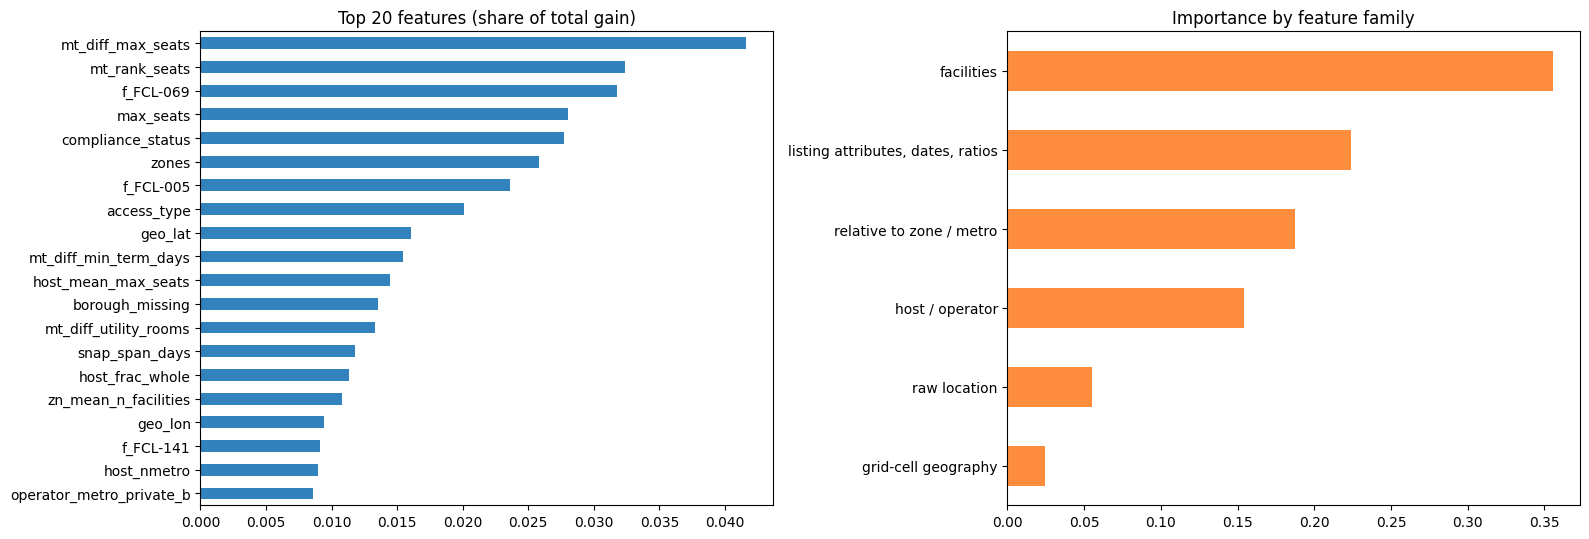

geography-cell features in the top 40: 0 of 8
facility flags: 145 columns share 35.5% of the gain (one flag alone is tiny)


In [13]:
# ============ Step 3c: feature importance ============
rng = np.random.RandomState(SEED); samp = rng.choice(len(y), min(N_SAMPLE, len(y)), replace=False)
Xs3, Xs4, ys, gs = X3.iloc[samp], X4.iloc[samp], y[samp], groups[samp]
quick = xgb.XGBClassifier(n_estimators=40 if QUICK else 150, learning_rate=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.5, tree_method='hist', n_jobs=N_JOBS)
quick.fit(Xs4, ys)
imp = pd.Series(quick.get_booster().get_score(importance_type='gain')).reindex(X4.columns).fillna(0); imp = imp / imp.sum()
def family(c):
    if c in GEO_COLS: return 'grid-cell geography'
    if c.startswith('f_') or c == 'n_facilities': return 'facilities'
    if c.startswith(('zn_', 'mt_')): return 'relative to zone / metro'
    if c.startswith('host_') or c.startswith('operator'): return 'host / operator'
    if c in ('zone', 'metro', 'borough', 'geo_lat', 'geo_lon', 'borough_missing'): return 'raw location'
    return 'listing attributes, dates, ratios'
fam = imp.groupby(imp.index.map(family)).sum().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
imp.sort_values().tail(20).plot.barh(ax=ax[0], color='#3182bd'); ax[0].set_title('Top 20 features (share of total gain)')
fam.plot.barh(ax=ax[1], color='#fd8d3c'); ax[1].set_title('Importance by feature family')
plt.tight_layout(); plt.show()
print('geography-cell features in the top 40: %d of %d' % (sum(c in GEO_COLS for c in imp.sort_values().tail(40).index), len(GEO_COLS)))
print('facility flags: %d columns share %.1f%% of the gain (one flag alone is tiny)' % (sum(c.startswith('f_') for c in X4), 100 * fam.get('facilities', 0)))

# Validation design

In [15]:
# ============ Step 4: honest validation = host-grouped folds ============
CV_RANDOM  = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xs3, ys))              # ignores hosts
CV_GROUPED = list(StratifiedGroupKFold(3, shuffle=True, random_state=SEED).split(Xs3, ys, gs))      # a host never spans two folds

def cv_eval(est, Xs, cv, name):
    # out-of-fold probabilities for every sample row, plus the three metrics used in this notebook
    t0 = time.time(); P = cross_val_predict(est, Xs, ys, cv=cv, method='predict_proba')
    return dict(model=name, **{'macro-F1': f1_score(ys, P.argmax(1), average='macro'), 'accuracy': accuracy_score(ys, P.argmax(1)),
                               'log-loss': log_loss(ys, P), 'seconds': time.time() - t0}), P

probe = xgb.XGBClassifier(n_estimators=40 if QUICK else 120, learning_rate=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.5, tree_method='hist', n_jobs=N_JOBS)
r_rand, _ = cv_eval(probe, Xs3, CV_RANDOM, 'random folds'); r_grp, _ = cv_eval(probe, Xs3, CV_GROUPED, 'host-grouped folds')
print(pd.DataFrame([r_rand, r_grp]).set_index('model').round(4))
print('\nrandom folds overstate macro-F1 by %.3f on this sample. Earlier, with all rows and 5 folds, random CV said 0.743 while the leaderboard gave ~0.70.' % (r_rand['macro-F1'] - r_grp['macro-F1']))
assert all(not set(gs[a]) & set(gs[b]) for a, b in CV_GROUPED)          # grouped folds: no host in both parts
print('host-grouped folds: %d hosts, no host appears on both sides of any split' % len(np.unique(gs)))

                    macro-F1  accuracy  log-loss  seconds
model                                                    
random folds          0.6862    0.6922    0.7215  58.1332
host-grouped folds    0.6738    0.6804    0.7438  54.3547

random folds overstate macro-F1 by 0.012 on this sample. Earlier, with all rows and 5 folds, random CV said 0.743 while the leaderboard gave ~0.70.
host-grouped folds: 50999 hosts, no host appears on both sides of any split


# Building models

In [16]:
# ============ Step 5 / Rung 0 and Model 1: dummy baseline + logistic regression pipeline ============
RESULTS, OOF = [], {}                                                # collected for the comparison table (cell after Model 3)
def log1p_clip(a): return np.log1p(np.clip(a, 0, None))             # log transform for heavy-tailed, non-negative columns
LOG_COLS = [c for c in ['review_count', 'review_count_12m', 'review_count_30d', 'review_count_prev_yr', 'reviews_per_month', 'booked_load',
                        'min_term_days', 'min_term_avg', 'max_term_avg', 'max_term_clip', 'host_size', 'zn_size', 'cell_n', 'cell_hosts',
                        'host_mean_review_count', 'open_slots_a', 'open_slots_d', 'host_mean_open_slots_d'] if c in X3.columns]
LOW_CATS = ['operator_class', 'space_class', 'access_type', 'compliance_status', 'metro', 'bookable']   # small categorical columns -> one-hot
NUM_COLS = [c for c in X3.columns if c not in CATS and c not in LOG_COLS]

def make_lr(C=1.0):
    pre = ColumnTransformer([
        ('log', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', FunctionTransformer(log1p_clip)), ('sc', StandardScaler())]), LOG_COLS),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), NUM_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=100), LOW_CATS)])
    return Pipeline([('prep', pre), ('clf', LogisticRegression(C=C, max_iter=200))])

# rung 0: the floor
r, P = cv_eval(DummyClassifier(strategy='prior'), Xs3, CV_GROUPED, 'Dummy (majority class)')
RESULTS.append(r); OOF['Dummy'] = P
# model 1: tune C with a grid search on the host-grouped folds
grid = GridSearchCV(make_lr(), {'clf__C': [0.03, 0.3, 3.0]}, cv=CV_GROUPED, scoring='f1_macro', refit=False).fit(Xs3, ys)
print(pd.DataFrame(grid.cv_results_)[['param_clf__C', 'mean_test_score']].round(4).to_string(index=False), '\nbest:', grid.best_params_)
r, P = cv_eval(make_lr(grid.best_params_['clf__C']), Xs3, CV_GROUPED, 'Model 1: Logistic regression')
RESULTS.append(r); OOF['LR'] = P
print(pd.DataFrame(RESULTS).set_index('model').round(4))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

 param_clf__C  mean_test_score
         0.03           0.6405
         0.30           0.6461
         3.00           0.6466 
best: {'clf__C': 3.0}


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

                              macro-F1  accuracy  log-loss  seconds
model                                                              
Dummy (majority class)          0.1129    0.2915    1.3808   0.1780
Model 1: Logistic regression    0.6466    0.6535    0.8159  89.7682


# Model 2

In [17]:
# ============ Step 5 / Model 2: decision tree (overfits) -> random forest (tuned) ============
def tree_pipe(est): return Pipeline([('imp', SimpleImputer(strategy='constant', fill_value=-1)), ('m', est)])   # trees need no scaling, only a NaN fill
tr0, va0 = CV_GROUPED[0]
dt = tree_pipe(DecisionTreeClassifier(random_state=0)).fit(Xs3.iloc[tr0], ys[tr0])
print('unrestricted tree: train macro-F1 %.3f vs validation %.3f  -> memorises the training data' % (
      f1_score(ys[tr0], dt.predict(Xs3.iloc[tr0]), average='macro'), f1_score(ys[va0], dt.predict(Xs3.iloc[va0]), average='macro')))
r, P = cv_eval(tree_pipe(DecisionTreeClassifier(min_samples_leaf=50, max_depth=14, random_state=0)), Xs3, CV_GROUPED, 'Decision tree (depth<=14, leaf>=50)')
RESULTS.append(r); OOF['Tree'] = P

rf_space = {'m__max_depth': [16, 24, None], 'm__min_samples_leaf': [3, 5, 10, 20], 'm__max_features': [0.1, 0.2, 0.33]}
rf_search = RandomizedSearchCV(tree_pipe(RandomForestClassifier(n_estimators=40 if QUICK else 100, n_jobs=N_JOBS, random_state=0)), rf_space,
                               n_iter=N_ITER['rf'], cv=CV_GROUPED, scoring='f1_macro', random_state=SEED, refit=False).fit(Xs3, ys)
print(pd.DataFrame(rf_search.cv_results_)[['param_m__max_depth', 'param_m__min_samples_leaf', 'param_m__max_features', 'mean_test_score']].sort_values('mean_test_score', ascending=False).round(4).to_string(index=False))
best_rf = {k.replace('m__', ''): v for k, v in rf_search.best_params_.items()}
r, P = cv_eval(tree_pipe(RandomForestClassifier(n_estimators=40 if QUICK else 200, n_jobs=N_JOBS, random_state=0, **best_rf)), Xs3, CV_GROUPED, 'Model 2: Random forest (tuned)')
RESULTS.append(r); OOF['RF'] = P
print(pd.DataFrame(RESULTS).set_index('model').round(4))

unrestricted tree: train macro-F1 1.000 vs validation 0.558  -> memorises the training data
param_m__max_depth  param_m__min_samples_leaf  param_m__max_features  mean_test_score
                24                          3                   0.20           0.6643
              None                         10                   0.20           0.6610
              None                         20                   0.33           0.6601
                24                          5                   0.10           0.6586
              None                         20                   0.20           0.6562
              None                         10                   0.10           0.6548
                                     macro-F1  accuracy  log-loss   seconds
model                                                                      
Dummy (majority class)                 0.1129    0.2915    1.3808    0.1780
Model 1: Logistic regression           0.6466    0.6535    0.8159   89.7682
De

# Model 3

In [18]:
# ============ Step 5 / Model 3: XGBoost default vs tuned (base features, no geography yet) ============
def make_xgb(**kw):
    p = dict(n_estimators=40 if QUICK else 150, learning_rate=0.1, tree_method='hist', n_jobs=N_JOBS, random_state=0); p.update(kw)
    return xgb.XGBClassifier(**p)
r, P = cv_eval(make_xgb(), Xs3, CV_GROUPED, 'XGBoost (default settings)'); RESULTS.append(r); OOF['XGB0'] = P

xgb_space = {'max_depth': randint(4, 9), 'min_child_weight': [5, 20, 50, 100], 'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.3, 0.6),
             'reg_lambda': loguniform(1, 100), 'gamma': [0, 0.5, 1, 2]}
xgb_search = RandomizedSearchCV(make_xgb(), xgb_space, n_iter=N_ITER['xgb'], cv=CV_GROUPED, scoring='f1_macro', random_state=SEED, refit=False).fit(Xs3, ys)
show = pd.DataFrame(xgb_search.cv_results_)
print(show[[c for c in show if c.startswith('param_')] + ['mean_test_score']].sort_values('mean_test_score', ascending=False).round(3).to_string(index=False))
BEST_XGB = xgb_search.best_params_; print('\nbest parameters:', {k: (round(v, 3) if isinstance(v, float) else v) for k, v in BEST_XGB.items()})
r, P = cv_eval(make_xgb(**BEST_XGB), Xs3, CV_GROUPED, 'Model 3: XGBoost (tuned)'); RESULTS.append(r); OOF['XGB'] = P
print(pd.DataFrame(RESULTS).set_index('model').round(4))

 param_colsample_bytree  param_gamma  param_max_depth  param_min_child_weight  param_reg_lambda  param_subsample  mean_test_score
                  0.328          1.0                8                       5             1.349            0.980            0.683
                  0.314          1.0                6                      50             1.901            0.717            0.674
                  0.520          0.5                6                     100            10.677            0.837            0.673
                  0.879          0.5                5                       5             1.076            0.692            0.673
                  0.525          0.0                6                     100            15.751            0.662            0.672
                  0.394          1.0                6                     100             4.650            0.657            0.671
                  0.691          0.0                5                     100            4

# Comparing models and testing geography idea

                                     macro-F1  accuracy  log-loss   seconds
model                                                                      
Dummy (majority class)                 0.1129    0.2915    1.3808    0.1780
Model 1: Logistic regression           0.6466    0.6535    0.8159   89.7682
Decision tree (depth<=14, leaf>=50)    0.6131    0.6168    1.2425   17.2663
Model 2: Random forest (tuned)         0.6650    0.6711    0.7780  259.6012
XGBoost (default settings)             0.6744    0.6801    0.7333   80.9155
Model 3: XGBoost (tuned)               0.6828    0.6877    0.7186   88.0548
Model 3 + geography features           0.6846    0.6897    0.7137   99.2527


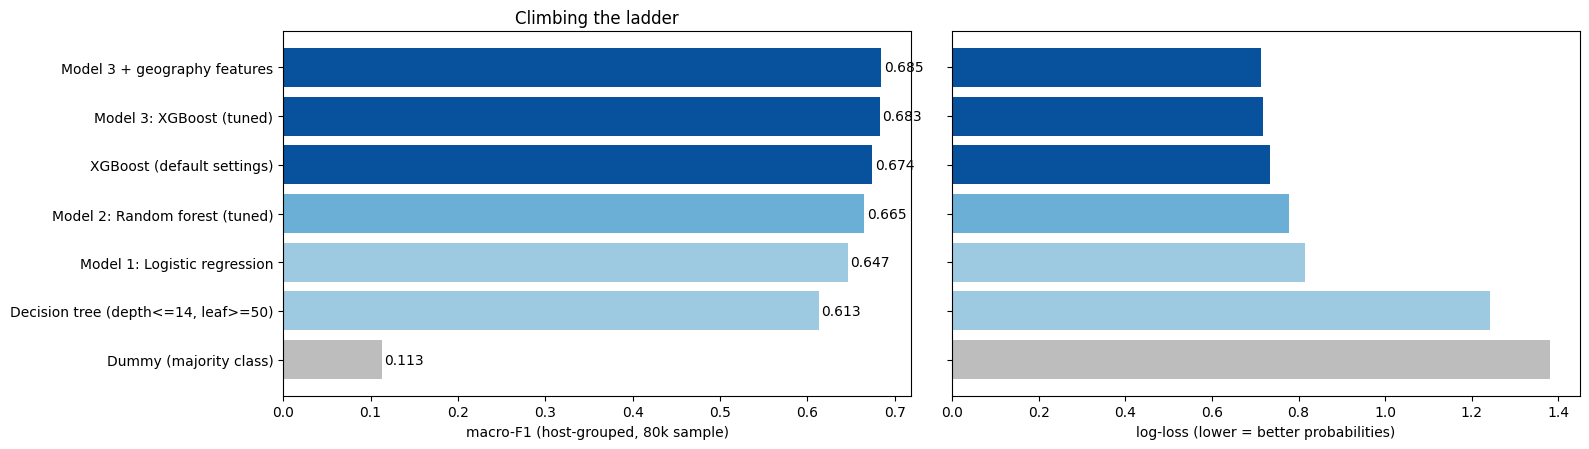

geography features: macro-F1 +0.0018, log-loss -0.0049  (same model, same folds; leaderboard gain in our earlier runs was about +0.002)


In [19]:
# ============ Step 5: model comparison + geography ablation ============
r, P = cv_eval(make_xgb(**BEST_XGB), Xs4, CV_GROUPED, 'Model 3 + geography features'); RESULTS.append(r); OOF['XGB_geo'] = P
cmp = pd.DataFrame(RESULTS).set_index('model').round(4); print(cmp.to_string())
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6)); order = cmp['macro-F1'].sort_values().index
colors = ['#bdbdbd' if 'Dummy' in m else '#9ecae1' if ('Logistic' in m or 'tree' in m) else '#6baed6' if 'forest' in m else '#08519c' for m in order]
ax[0].barh(order, cmp.loc[order, 'macro-F1'], color=colors); ax[0].set_xlabel('macro-F1 (host-grouped, 80k sample)'); ax[0].set_title('Climbing the ladder')
for i, v in enumerate(cmp.loc[order, 'macro-F1']): ax[0].text(v + .003, i, f'{v:.3f}', va='center')
ax[1].barh(order, cmp.loc[order, 'log-loss'], color=colors); ax[1].set_xlabel('log-loss (lower = better probabilities)'); ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()
g = cmp.loc['Model 3 + geography features', 'macro-F1'] - cmp.loc['Model 3: XGBoost (tuned)', 'macro-F1']
print('geography features: macro-F1 %+.4f, log-loss %+.4f  (same model, same folds; leaderboard gain in our earlier runs was about +0.002)' % (
      g, cmp.loc['Model 3 + geography features', 'log-loss'] - cmp.loc['Model 3: XGBoost (tuned)', 'log-loss']))

macro-F1 by number of training rows:
13224    0.6600
26449    0.6749
52899    0.6840


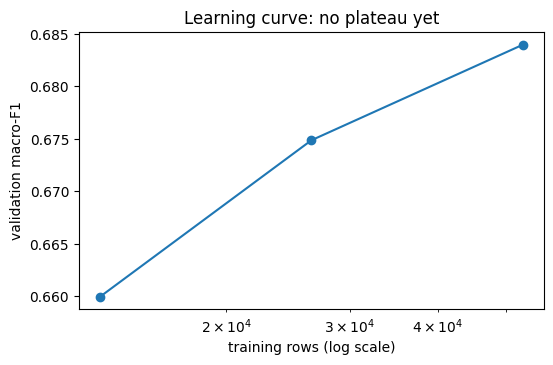

In [20]:
# ============ Step 5: does more data help? (learning curve of the tuned booster with geography) ============
lc = {}
for frac in [0.25, 0.5, 1.0]:
    sc = []
    for tr, va in CV_GROUPED:
        sub = np.random.RandomState(SEED).choice(tr, int(len(tr) * frac), replace=False)
        m = make_xgb(**BEST_XGB).fit(Xs4.iloc[sub], ys[sub]); sc.append(f1_score(ys[va], m.predict(Xs4.iloc[va]), average='macro'))
    lc[int(frac * len(CV_GROUPED[0][0]))] = np.mean(sc)
lc = pd.Series(lc); print('macro-F1 by number of training rows:'); print(lc.round(4).to_string())
plt.figure(figsize=(6, 3.6)); lc.plot(marker='o', logx=True); plt.xlabel('training rows (log scale)'); plt.ylabel('validation macro-F1'); plt.title('Learning curve: no plateau yet'); plt.show()

# Final Model

In [21]:
# ============ Step 6: stage-1 trainer shared by the three boosters ============
S1 = {}                                                              # name -> {'oof': (n,4), 'test': (n_test,4)}
def fit_with_early_stopping(model, Xa, ya, Xb, yb):
    if isinstance(model, xgb.XGBClassifier): model.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    else: model.fit(Xa, ya, eval_set=[(Xb, yb)], callbacks=[lgb.early_stopping(50, verbose=False)])
    return model

def run_stage1(name, make_model, Xtr_all, Xte_all):
    oof, tst, t0 = np.zeros((len(y), 4)), np.zeros((len(Xte_all), 4)), time.time()
    for k in range(5):
        tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
        a, b = next(GroupShuffleSplit(1, test_size=0.1, random_state=k).split(tr, groups=groups[tr]))     # inner host-grouped split for early stopping
        m = fit_with_early_stopping(make_model(), Xtr_all.iloc[tr[a]], y[tr[a]], Xtr_all.iloc[tr[b]], y[tr[b]])
        oof[va] = m.predict_proba(Xtr_all.iloc[va]); tst += m.predict_proba(Xte_all) / 5
        print(f'  {name} fold {k}: macro-F1 {f1_score(y[va], oof[va].argmax(1), average="macro"):.4f}  trees {getattr(m, "best_iteration_", getattr(m, "best_iteration", "?"))}  ({(time.time() - t0) / 60:.1f} min)', flush=True)
    S1[name] = {'oof': oof, 'test': tst}
    print(f'{name}: out-of-fold macro-F1 {f1_score(y, oof.argmax(1), average="macro"):.4f} | log-loss {log_loss(y, oof):.4f} | {(time.time() - t0) / 60:.1f} min\n')

def make_boosterA():
    return xgb.XGBClassifier(n_estimators=MAX_TREES, learning_rate=0.1, tree_method='hist', n_jobs=N_JOBS, early_stopping_rounds=50, eval_metric='mlogloss', random_state=0, **BEST_XGB)
run_stage1('A: XGBoost (tuned)', make_boosterA, X4, Xt4)

  A: XGBoost (tuned) fold 0: macro-F1 0.7135  trees 764  (5.8 min)
  A: XGBoost (tuned) fold 1: macro-F1 0.7074  trees 660  (11.3 min)
  A: XGBoost (tuned) fold 2: macro-F1 0.7181  trees 707  (16.7 min)
  A: XGBoost (tuned) fold 3: macro-F1 0.7116  trees 556  (22.3 min)
  A: XGBoost (tuned) fold 4: macro-F1 0.7159  trees 917  (29.3 min)
A: XGBoost (tuned): out-of-fold macro-F1 0.7133 | log-loss 0.6522 | 29.3 min



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [24]:
# ============ Step 6: Booster B = XGBoost with different randomness / regularisation ============
def make_boosterB():
    p = dict(BEST_XGB); p.update(gamma=1.0, colsample_bytree=0.8)
    return xgb.XGBClassifier(n_estimators=MAX_TREES, learning_rate=0.1, tree_method='hist', n_jobs=N_JOBS, early_stopping_rounds=50, eval_metric='mlogloss',
                             colsample_bynode=0.6, random_state=7, **p)
run_stage1('B: XGBoost (gamma, column sampling)', make_boosterB, X4, Xt4)

  B: XGBoost (gamma, column sampling) fold 0: macro-F1 0.7126  trees 1246  (7.5 min)
  B: XGBoost (gamma, column sampling) fold 1: macro-F1 0.7072  trees 777  (13.6 min)
  B: XGBoost (gamma, column sampling) fold 2: macro-F1 0.7167  trees 627  (19.1 min)
  B: XGBoost (gamma, column sampling) fold 3: macro-F1 0.7134  trees 558  (24.2 min)
  B: XGBoost (gamma, column sampling) fold 4: macro-F1 0.7136  trees 581  (29.3 min)
B: XGBoost (gamma, column sampling): out-of-fold macro-F1 0.7127 | log-loss 0.6527 | 29.3 min



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [27]:
# ============ Step 6: Booster C = LightGBM (leaf-wise growth) ============
def make_boosterC():
    return lgb.LGBMClassifier(n_estimators=MAX_TREES, learning_rate=0.08, num_leaves=63, min_child_samples=50, colsample_bytree=0.5, subsample=0.8,
                              subsample_freq=1, reg_lambda=10, n_jobs=N_JOBS, verbose=-1, random_state=0)
run_stage1('C: LightGBM', make_boosterC, X4, Xt4)

  C: LightGBM fold 0: macro-F1 0.7121  trees 803  (6.9 min)
  C: LightGBM fold 1: macro-F1 0.7078  trees 576  (12.2 min)
  C: LightGBM fold 2: macro-F1 0.7192  trees 692  (18.2 min)
  C: LightGBM fold 3: macro-F1 0.7130  trees 708  (24.3 min)
  C: LightGBM fold 4: macro-F1 0.7143  trees 577  (29.5 min)
C: LightGBM: out-of-fold macro-F1 0.7133 | log-loss 0.6502 | 29.5 min



In [28]:
# ============ Step 6: blend with log-loss-optimal weights ============
names = list(S1)
def blend_weights(Ps):
    f = lambda z: log_loss(y, sum(w * P for w, P in zip(np.exp(z) / np.exp(z).sum(), Ps)))
    z = minimize(f, np.zeros(len(Ps)), method='Nelder-Mead', options=dict(maxiter=300)).x
    return np.exp(z) / np.exp(z).sum()
bw = blend_weights([S1[n]['oof'] for n in names])
B_oof = sum(w * S1[n]['oof'] for w, n in zip(bw, names)); B_test = sum(w * S1[n]['test'] for w, n in zip(bw, names))
macro = lambda P, w=np.ones(4): f1_score(y, (P * w).argmax(1), average='macro')
tab = pd.DataFrame({'blend weight': list(bw) + [np.nan], 'macro-F1': [macro(S1[n]['oof']) for n in names] + [macro(B_oof)],
                    'log-loss': [log_loss(y, S1[n]['oof']) for n in names] + [log_loss(y, B_oof)]}, index=names + ['BLEND of the three']).round(4)
print(tab.to_string())
pair = [np.mean(S1[a]['oof'].argmax(1) != S1[b]['oof'].argmax(1)) for i, a in enumerate(names) for b in names[i + 1:]]
print('\nthe boosters disagree on %.1f%%-%.1f%% of listings: enough difference for averaging to help, not much to gain from many more copies' % (100 * min(pair), 100 * max(pair)))

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: T

                                     blend weight  macro-F1  log-loss
A: XGBoost (tuned)                         0.2818    0.7133    0.6522
B: XGBoost (gamma, column sampling)        0.2735    0.7127    0.6527
C: LightGBM                                0.4446    0.7133    0.6502
BLEND of the three                            NaN    0.7163    0.6444

the boosters disagree on 7.6%-8.5% of listings: enough difference for averaging to help, not much to gain from many more copies


In [29]:
# ============ Step 6: stage 2 = host pooling on top of the blended probabilities ============
def stage2_features(P, hk, seats, metro):
    d = pd.DataFrame(P, columns=['p0', 'p1', 'p2', 'p3']); d['hk'] = hk.values; d['seats'] = seats.values; d['metro'] = metro.values
    g = d.groupby('hk'); n = g['p0'].transform('size'); d['host_n'] = n
    for c in ['p0', 'p1', 'p2', 'p3']:
        s = g[c].transform('sum')
        d['sib_' + c] = np.where(n > 1, (s - d[c]) / (n - 1).clip(lower=1), np.nan)          # mean of the OTHER listings of the host
        d['hostmean_' + c] = s / n
    d['exp_own'] = d[['p0', 'p1', 'p2', 'p3']].values @ np.arange(4)                          # expected tier of the listing itself
    d['exp_sib'] = d[['sib_p0', 'sib_p1', 'sib_p2', 'sib_p3']].values @ np.arange(4)          # expected tier of its siblings
    d['exp_sib_std'] = g['exp_own'].transform('std'); d['seats_diff_host'] = d['seats'] - g['seats'].transform('mean')
    return d.drop(columns=['hk'])

S2_PARAMS = dict(n_estimators=250, learning_rate=0.05, num_leaves=15, min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                 reg_lambda=10, verbose=-1, n_jobs=N_JOBS, random_state=0)
D_tr = stage2_features(B_oof, hk_train, X4['max_seats'], X4['metro'])
D_te = stage2_features(B_test, hk_te, Xt4['max_seats'], Xt4['metro'])
P2_oof = np.zeros((len(y), 4))
for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=3).split(D_tr, y, groups):             # host-grouped, on out-of-fold inputs
    P2_oof[b] = lgb.LGBMClassifier(**S2_PARAMS).fit(D_tr.iloc[a], y[a]).predict_proba(D_tr.iloc[b])
P2_test = lgb.LGBMClassifier(**S2_PARAMS).fit(D_tr, y).predict_proba(D_te)

multi = (D_tr.host_n > 1).values
print('macro-F1  blend (stage 1): %.4f  ->  after host pooling: %.4f   (log-loss %.4f -> %.4f)' % (macro(B_oof), macro(P2_oof), log_loss(y, B_oof), log_loss(y, P2_oof)))
print('hosts with 2+ listings (%.0f%% of rows): %.4f -> %.4f | single-listing hosts: %.4f -> %.4f   (pooling can only help where siblings exist)' % (
      100 * multi.mean(), f1_score(y[multi], B_oof[multi].argmax(1), average='macro'), f1_score(y[multi], P2_oof[multi].argmax(1), average='macro'),
      f1_score(y[~multi], B_oof[~multi].argmax(1), average='macro'), f1_score(y[~multi], P2_oof[~multi].argmax(1), average='macro')))

macro-F1  blend (stage 1): 0.7163  ->  after host pooling: 0.7214   (log-loss 0.6444 -> 0.6356)
hosts with 2+ listings (64% of rows): 0.7229 -> 0.7280 | single-listing hosts: 0.7019 -> 0.7069   (pooling can only help where siblings exist)


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [30]:
# ============ Step 6: class weights tuned for macro-F1 ============
def tune_weights(P):
    w, best = np.ones(4), macro(P)
    for _ in range(3):                                               # a few sweeps of coordinate search
        for c in range(1, 4):
            for v in np.arange(0.7, 1.6, 0.02):
                w2 = w.copy(); w2[c] = v; s = macro(P, w2)
                if s > best: best, w = s, w2
    return w, best
W_CLS, f_tuned = tune_weights(P2_oof)
pred_oof = (P2_oof * W_CLS).argmax(1)
print('class weights', W_CLS.round(2), '| macro-F1 %.4f -> %.4f | accuracy %.4f -> %.4f' % (macro(P2_oof), f_tuned, accuracy_score(y, P2_oof.argmax(1)), accuracy_score(y, pred_oof)))
cmp_cls = pd.DataFrame({'F1 before': f1_score(y, P2_oof.argmax(1), average=None), 'F1 after': f1_score(y, pred_oof, average=None)}, index=[f'tier {c}' for c in range(1, 5)]).round(3)
print(cmp_cls.to_string(), '\n(weights trade a little accuracy for tier-3 recall; the weighted rule is what we submit)')

class weights [1.   0.98 1.22 1.  ] | macro-F1 0.7214 -> 0.7233 | accuracy 0.7237 -> 0.7221
        F1 before  F1 after
tier 1      0.819     0.819
tier 2      0.688     0.678
tier 3      0.576     0.598
tier 4      0.804     0.798 
(weights trade a little accuracy for tier-3 recall; the weighted rule is what we submit)


        precision  recall     F1  support
tier 1      0.817   0.821  0.819    66889
tier 2      0.673   0.684  0.678    81530
tier 3      0.570   0.629  0.598    60839
tier 4      0.849   0.753  0.798    70488

error rate 0.278 | 93.5% of errors are exactly one tier off | 1.81% of rows are two or more tiers off

accuracy by confidence band:
            accuracy    rows
(0.0, 0.4]     0.359    2931
(0.4, 0.5]     0.462   23432
(0.5, 0.6]     0.543   55221
(0.6, 0.7]     0.647   51669
(0.7, 0.8]     0.744   45684
(0.8, 1.0]     0.920  100809


/tmp/ipykernel_58/4068014466.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  band = pd.Series(~err).groupby(pd.cut(conf, [0, .4, .5, .6, .7, .8, 1.0])).agg(['mean', 'size']).round(3); band.columns = ['accuracy', 'rows']; print('\naccuracy by confidence band:'); print(band.to_string())


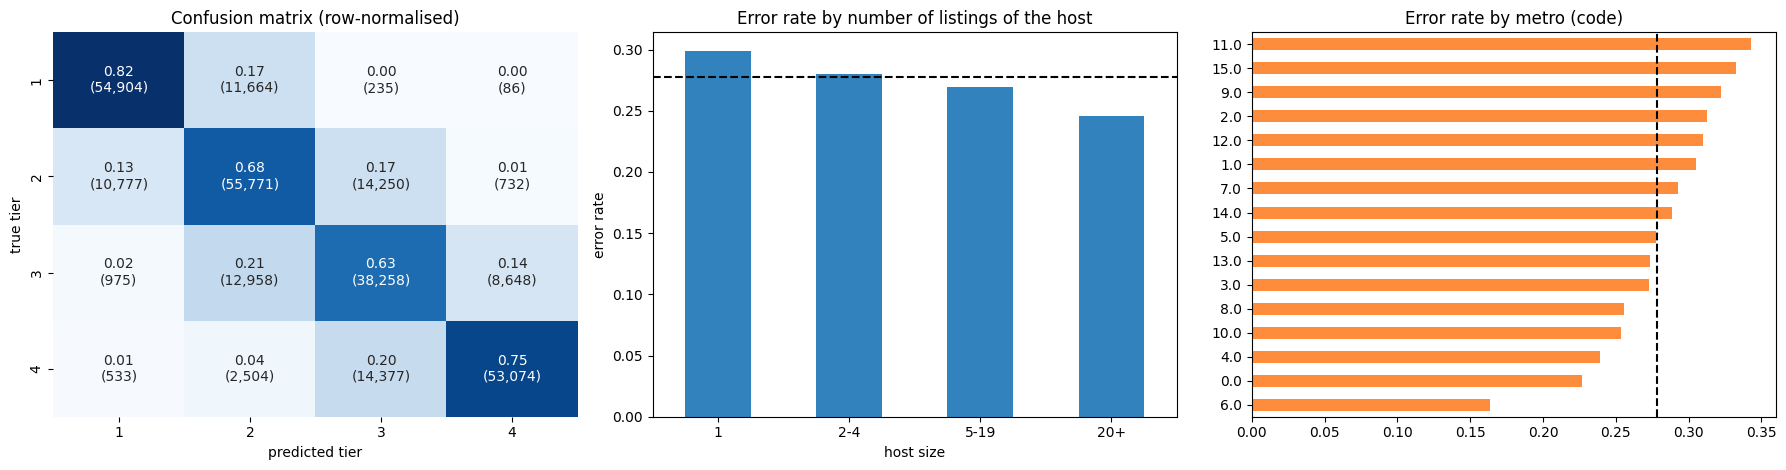

In [31]:
# ============ Step 7: confusion matrix, confidence, error by segment ============
cm = confusion_matrix(y, pred_oof); cmn = cm / cm.sum(1, keepdims=True); pr, rc, f1c, sup = precision_recall_fscore_support(y, pred_oof)
report = pd.DataFrame({'precision': pr, 'recall': rc, 'F1': f1c, 'support': sup}, index=[f'tier {c}' for c in range(1, 5)]).round(3); print(report.to_string())
err = pred_oof != y; conf = P2_oof.max(1)
print('\nerror rate %.3f | %.1f%% of errors are exactly one tier off | %.2f%% of rows are two or more tiers off' % (err.mean(), 100 * (np.abs(pred_oof - y) == 1)[err].mean(), 100 * (np.abs(pred_oof - y) >= 2).mean()))
band = pd.Series(~err).groupby(pd.cut(conf, [0, .4, .5, .6, .7, .8, 1.0])).agg(['mean', 'size']).round(3); band.columns = ['accuracy', 'rows']; print('\naccuracy by confidence band:'); print(band.to_string())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.heatmap(cmn, annot=np.array([[f'{cmn[i, j]:.2f}\n({cm[i, j]:,})' for j in range(4)] for i in range(4)]), fmt='', cmap='Blues', cbar=False, ax=ax[0], xticklabels=range(1, 5), yticklabels=range(1, 5))
ax[0].set_xlabel('predicted tier'); ax[0].set_ylabel('true tier'); ax[0].set_title('Confusion matrix (row-normalised)')
seg = pd.DataFrame({'host size': pd.cut(D_tr.host_n, [0, 1, 4, 19, 1e9], labels=['1', '2-4', '5-19', '20+']), 'err': err}).groupby('host size', observed=True).err.mean()
seg.plot.bar(ax=ax[1], rot=0, color='#3182bd'); ax[1].axhline(err.mean(), color='k', ls='--'); ax[1].set_title('Error rate by number of listings of the host'); ax[1].set_ylabel('error rate')
metro_err = pd.Series(err).groupby(X4['metro'].values).mean().sort_values(); metro_err.plot.barh(ax=ax[2], color='#fd8d3c'); ax[2].set_title('Error rate by metro (code)'); ax[2].axvline(err.mean(), color='k', ls='--')
plt.tight_layout(); plt.show()

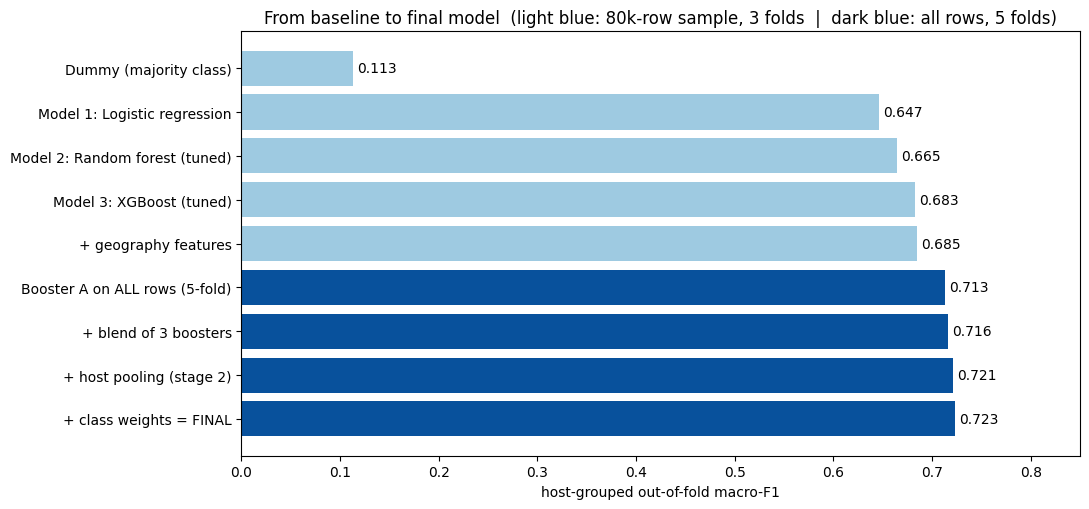

                          step  macro-F1 protocol
        Dummy (majority class)    0.1129        A
  Model 1: Logistic regression    0.6466        A
Model 2: Random forest (tuned)    0.6650        A
      Model 3: XGBoost (tuned)    0.6828        A
          + geography features    0.6846        A
Booster A on ALL rows (5-fold)    0.7133        B
         + blend of 3 boosters    0.7163        B
      + host pooling (stage 2)    0.7214        B
       + class weights = FINAL    0.7233        B


In [32]:
# ============ Step 8a: the ladder, from the dummy baseline to the final model ============
ladder = [('Dummy (majority class)', cmp.loc['Dummy (majority class)', 'macro-F1'], 'A'),
          ('Model 1: Logistic regression', cmp.loc['Model 1: Logistic regression', 'macro-F1'], 'A'),
          ('Model 2: Random forest (tuned)', cmp.loc['Model 2: Random forest (tuned)', 'macro-F1'], 'A'),
          ('Model 3: XGBoost (tuned)', cmp.loc['Model 3: XGBoost (tuned)', 'macro-F1'], 'A'),
          ('+ geography features', cmp.loc['Model 3 + geography features', 'macro-F1'], 'A'),
          ('Booster A on ALL rows (5-fold)', macro(S1[names[0]]['oof']), 'B'),
          ('+ blend of 3 boosters', macro(B_oof), 'B'), ('+ host pooling (stage 2)', macro(P2_oof), 'B'), ('+ class weights = FINAL', f_tuned, 'B')]
lad = pd.DataFrame(ladder, columns=['step', 'macro-F1', 'protocol'])
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.barh(lad.step[::-1], lad['macro-F1'][::-1], color=['#08519c' if p == 'B' else '#9ecae1' for p in lad.protocol[::-1]])
for i, v in enumerate(lad['macro-F1'][::-1]): ax.text(v + .004, i, f'{v:.3f}', va='center')
ax.set_xlim(0, .85); ax.set_xlabel('host-grouped out-of-fold macro-F1')
ax.set_title('From baseline to final model  (light blue: 80k-row sample, 3 folds  |  dark blue: all rows, 5 folds)')
plt.tight_layout(); plt.show()
print(lad.round(4).to_string(index=False))

In [33]:
# ============ Step 8b: write the submission produced BY THIS NOTEBOOK ============
pred_test = (P2_test * W_CLS).argmax(1) + 1                                   # back to tiers 1..4
sub = pd.DataFrame({'ID': test['space_id'].values, 'price_tier': pred_test})
sub.to_csv('submission.csv', index=False)
assert sub.ID.is_unique and len(sub) == len(test) and set(sub.price_tier) <= {1, 2, 3, 4}
print('submission.csv written:', sub.shape)
print('predicted tier shares :', sub.price_tier.value_counts(normalize=True).sort_index().round(3).to_dict())
print('training tier shares  :', train.price_tier.value_counts(normalize=True).sort_index().round(3).to_dict())
print('out-of-fold macro-F1 of the final pipeline: %.4f  (expected leaderboard score is about 0.001 lower: new hosts and a different location mix)' % f_tuned)
sub.head()

submission.csv written: (114538, 2)
predicted tier shares : {1: 0.226, 2: 0.32, 3: 0.234, 4: 0.219}
training tier shares  : {1: 0.239, 2: 0.291, 3: 0.217, 4: 0.252}
out-of-fold macro-F1 of the final pipeline: 0.7233  (expected leaderboard score is about 0.001 lower: new hosts and a different location mix)


,ID,price_tier
0,0,1
1,1,2
2,2,1
3,3,2
4,4,2


# End